## Hướng dẫn trình bày hiện hành — 2026-11-11

Experiment1=baseline; Experiment3=tuning. Kết quả Colab đã có evidence pin; các dòng NOT YET VERIFIED cũ là lịch sử lúc tạo. **Không Run All**. Cell tuning-switch hiện True do owner bật từ lần chạy trước; source/output giữ nguyên. Xem hai phần tổng hợp Markdown cuối notebook để xem kết quả không fit/predict. Hướng dẫn runtime hiện hành: [deployment](../docs/DEPLOYMENT_GUIDE.md).

# 03 — Huấn luyện trên Colab, lưu vào Google Drive

## 1. Runtime dùng chung với notebook 00–02

Đồng bộ source vào canonical Drive root, chọn kernel Colab và mount Drive theo
[hướng dẫn chung](../docs/phase3_colab.md). Không upload session package vào runtime.
Cell đầu chỉ kiểm môi trường/source và chuẩn bị workspace tạm; cell tiếp theo mới kiểm dữ liệu.
Đường dẫn tập trung ở `configs/runtime.json`; dòng locator dưới chỉ chỉ tới source trên Drive.
Khi source đổi, đồng bộ Drive rồi Restart Kernel. Không tự cài package hoặc tái tạo Phase 2.
Chạy riêng hai phần đầu để preflight/nạp dữ liệu; các cell mô hình chỉ chạy khi chủ động huấn luyện.

In [1]:
import runpy, platform
from pathlib import Path
if platform.system() != 'Linux' or not Path('/content').is_dir():
    raise RuntimeError('Chọn Google Colab kernel; /content phải là ổ tạm của runtime.')
DRIVE_ROOT = Path('/content/drive/MyDrive/ML_Projects/disease-prediction-ml')  # Locator sinh từ configs/runtime.json
entry = DRIVE_ROOT / 'src/data/colab_runtime.py'
if not entry.is_file():
    raise FileNotFoundError(f'Không thấy {entry}. Mount Drive và Publish source bằng prepare_colab_source.ps1; không upload script riêng.')
EXPECTED_RUNTIME_PAYLOAD = globals().get('EXPECTED_RUNTIME_PAYLOAD') or input('Paste RUNTIME_PAYLOAD_SHA256 from local Publish: ').strip()
RUNTIME = runpy.run_path(str(entry))['bootstrap_runtime'](DRIVE_ROOT, phase=3, expected_payload_sha256=EXPECTED_RUNTIME_PAYLOAD)
ROOT, runtime_paths = RUNTIME.paths.project_root, RUNTIME.paths

Stage A PASS | Colab Python 3.13.18 | Drive=/content/drive/MyDrive/ML_Projects/disease-prediction-ml | runtime/Drive read-write OK
Stage B PASS | imports=/content/disease-prediction-ml-runtime | source fingerprint=3d2905f3329c3486b435206d9a3e06bdb9a98dc21b7a6f0324880a6a93c583c0


In [5]:
from src.models.notebook import ColabTraining
session = ColabTraining.open(RUNTIME)

Stage C PASS | manifest=50308d250d874b1b653a71c31f38dece0ec9fbb4dbc9d94f68bc1461e80b8fe9 | 7 train/validation/metadata checksums OK


,Thông tin,Giá trị
0,Runtime,colab
1,Python,3.13.18
2,Scikit-learn,1.6.1
3,RAM khả dụng (GiB),11.259
4,CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
5,GPU phát hiện,[]
6,Drive đọc/ghi,True


Source workspace: /content/disease-prediction-ml-runtime
Source fingerprint: 3d2905f3329c3486b435206d9a3e06bdb9a98dc21b7a6f0324880a6a93c583c0
Dữ liệu / đầu ra Drive: /content/drive/MyDrive/ML_Projects/disease-prediction-ml
Checksum input hợp lệ; chỉ đọc train/validation, không mở CSV test.


## 2. Đọc train/validation đã khóa

Kiểm checksum và schema; cache cần thiết nằm ở ổ tạm Colab. Không đọc/copy CSV test.

In [9]:
session.load_data()
X_train, y_train, groups_train = session.data["train"]
X_val, y_val, groups_val = session.data["validation"]

Đang đọc train/validation và kiểm tra schema/group...


,Tập,Bản ghi,Lớp bệnh,Triệu chứng trước variance,Group
0,train,131248,587,375,117211
1,validation,28120,587,375,25127


Fingerprint processed: afde00ce35bf4fd31c9c76edcc3c8b64104e53fb81dd98d4a56d7b3a884b16b3
VarianceThreshold chỉ fit khi train; cache ở ổ tạm: /content/disease-prediction-ml-cache/phase3/50308d250d874b1b


## 3. Huấn luyện 5 mô hình

Mỗi mô hình có một cell riêng bên dưới. Pipeline chung gồm `VarianceThreshold(0)` và CSR;
lệnh `.fit(X_train, y_train)` hiển thị ngay trong mỗi cell, được helper thực thi khi cần fit mới.
Helper chỉ lo giới hạn tài nguyên, thời gian, checkpoint và predict validation theo batch.
Nếu checkpoint đã hoàn tất và khớp cấu hình, log ghi **REUSED**, không gọi lại `.fit()`.
Tham số lấy từ `configs/phase3.json`; muốn đổi tham số thì cập nhật config để tránh reuse nhầm.

In [10]:
import os
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from src.models.training import to_csr

seed = session.config["seed"]
workers = min(session.config["resources"]["max_workers"], os.cpu_count() or 1)

def make_pipeline(estimator):
    return Pipeline([
        ("variance", VarianceThreshold(threshold=0)),
        ("csr", FunctionTransformer(to_csr, validate=False, feature_names_out="one-to-one")),
        ("estimator", estimator),
    ])

In [6]:
# 1/5 — Logistic Regression
lr_pipeline = make_pipeline(LogisticRegression(
    random_state=seed, **session.config["models"]["logistic_regression"]))
display(lr_pipeline)
lr_result = session.train_model(
    "logistic_regression", lr_pipeline,
    fit=lambda model: model.fit(X_train, y_train))
del lr_pipeline  # Pipeline đã lưu trên Drive; giải phóng RAM.

Pipeline(steps=[('variance', VarianceThreshold(threshold=0)),
                ('csr',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function to_csr at 0x7b47685c8f40>)),
                ('estimator',
                 LogisticRegression(max_iter=200, random_state=42,
                                    solver='saga', tol=0.001))])

Experiment: baseline-v1-f8a5bfdb7b4c12cd
START logistic_regression: fit 131,248 dòng train; RAM khả dụng 11.30 GiB
RUNNING logistic_regression fit: 30s | peak RSS lấy mẫu 1167.6 MiB | RAM khả dụng 10.72 GiB
RUNNING logistic_regression fit: 60s | peak RSS lấy mẫu 1167.6 MiB | RAM khả dụng 10.74 GiB
RUNNING logistic_regression fit: 90s | peak RSS lấy mẫu 1167.6 MiB | RAM khả dụng 10.73 GiB
FITTED logistic_regression: 91.594s | features 375 → 318 | đã lưu Drive checkpoint
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in 

,model,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,n_retained_features,sampled_peak_rss_mb,warnings,error
0,logistic_regression,completed,0.83709,0.82742,0.77919,0.78781,0.83668,91.5942,2.15747,318,1167.63672,6,


In [7]:
# 2/5 — Random Forest
rf_pipeline = make_pipeline(RandomForestClassifier(
    random_state=seed, n_jobs=workers, **session.config["models"]["random_forest"]))
display(rf_pipeline)
rf_result = session.train_model(
    "random_forest", rf_pipeline,
    fit=lambda model: model.fit(X_train, y_train))
del rf_pipeline

Pipeline(steps=[('variance', VarianceThreshold(threshold=0)),
                ('csr',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function to_csr at 0x7b47685c8f40>)),
                ('estimator',
                 RandomForestClassifier(max_depth=24, max_leaf_nodes=512,
                                        min_samples_leaf=2, n_jobs=2,
                                        random_state=42))])

START random_forest: fit 131,248 dòng train; RAM khả dụng 11.30 GiB
FITTED random_forest: 15.101s | features 375 → 318 | đã lưu Drive checkpoint
  Validation: đã dự đoán 64/28,120 dòng
  Validation: đã dự đoán 20,608/28,120 dòng
  Validation: đã dự đoán 28,120/28,120 dòng
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
FINISHED random_forest: predict 20.684s | validation macro F1=0.49200


,model,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,n_retained_features,sampled_peak_rss_mb,warnings,error
0,random_forest,completed,0.70053,0.65965,0.44123,0.492,0.69931,15.10077,20.6839,318,1169.13281,3,


In [8]:
# 3/5 — Linear Support Vector Machine
svm_pipeline = make_pipeline(LinearSVC(
    random_state=seed, **session.config["models"]["linear_svc"]))
display(svm_pipeline)
svm_result = session.train_model(
    "linear_svc", svm_pipeline,
    fit=lambda model: model.fit(X_train, y_train))
del svm_pipeline

Pipeline(steps=[('variance', VarianceThreshold(threshold=0)),
                ('csr',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function to_csr at 0x7b47685c8f40>)),
                ('estimator',
                 LinearSVC(max_iter=3000, random_state=42, tol=0.001))])

START linear_svc: fit 131,248 dòng train; RAM khả dụng 11.20 GiB
RUNNING linear_svc fit: 30s | peak RSS lấy mẫu 1313.4 MiB | RAM khả dụng 11.22 GiB
RUNNING linear_svc fit: 60s | peak RSS lấy mẫu 1313.4 MiB | RAM khả dụng 11.20 GiB
FITTED linear_svc: 80.596s | features 375 → 318 | đã lưu Drive checkpoint
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7b47685dfe70>
  Validation: đã dự đoán 64/28,120 dòng
  Validation: đã dự đoán 28,120/28,120 dòng
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a

,model,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,n_retained_features,sampled_peak_rss_mb,warnings,error
0,linear_svc,completed,0.8308,0.81521,0.7814,0.78422,0.82987,80.59617,1.8265,318,1313.38281,5,


In [9]:
# 4/5 — K-Nearest Neighbors (predict theo batch để giảm RAM)
knn_pipeline = make_pipeline(KNeighborsClassifier(
    n_jobs=1, **session.config["models"]["knn"]))
display(knn_pipeline)
knn_result = session.train_model(
    "knn", knn_pipeline,
    fit=lambda model: model.fit(X_train, y_train))
del knn_pipeline

Pipeline(steps=[('variance', VarianceThreshold(threshold=0)),
                ('csr',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function to_csr at 0x7b47685c8f40>)),
                ('estimator',
                 KNeighborsClassifier(algorithm='brute', metric='manhattan',
                                      n_jobs=1, weights='distance'))])

START knn: fit 131,248 dòng train; RAM khả dụng 11.20 GiB
FITTED knn: 1.090s | features 375 → 318 | đã lưu Drive checkpoint
  Validation: đã dự đoán 64/28,120 dòng
  Validation: đã dự đoán 1,536/28,120 dòng
RUNNING knn validation: 30s | peak RSS lấy mẫu 469.1 MiB | RAM khả dụng 11.21 GiB
  Validation: đã dự đoán 3,008/28,120 dòng
  Validation: đã dự đoán 4,480/28,120 dòng
RUNNING knn validation: 60s | peak RSS lấy mẫu 469.1 MiB | RAM khả dụng 11.21 GiB
  Validation: đã dự đoán 5,888/28,120 dòng
  Validation: đã dự đoán 7,360/28,120 dòng
RUNNING knn validation: 90s | peak RSS lấy mẫu 469.1 MiB | RAM khả dụng 11.21 GiB
  Validation: đã dự đoán 8,832/28,120 dòng
  Validation: đã dự đoán 10,240/28,120 dòng
RUNNING knn validation: 120s | peak RSS lấy mẫu 469.1 MiB | RAM khả dụng 11.20 GiB
  Validation: đã dự đoán 11,712/28,120 dòng
  Validation: đã dự đoán 13,184/28,120 dòng
RUNNING knn validation: 151s | peak RSS lấy mẫu 469.1 MiB | RAM khả dụng 11.22 GiB
  Validation: đã dự đoán 14,656/28

,model,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,n_retained_features,sampled_peak_rss_mb,warnings,error
0,knn,completed,0.78314,0.78362,0.73192,0.73103,0.7868,1.09042,294.22415,318,1266.72656,31,


In [10]:
# 5/5 — Bernoulli Naive Bayes
nb_pipeline = make_pipeline(BernoulliNB(**session.config["models"]["bernoulli_nb"]))
display(nb_pipeline)
nb_result = session.train_model(
    "bernoulli_nb", nb_pipeline,
    fit=lambda model: model.fit(X_train, y_train))
del nb_pipeline

Pipeline(steps=[('variance', VarianceThreshold(threshold=0)),
                ('csr',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function to_csr at 0x7b47685c8f40>)),
                ('estimator', BernoulliNB(binarize=None))])

START bernoulli_nb: fit 131,248 dòng train; RAM khả dụng 11.21 GiB
FITTED bernoulli_nb: 1.836s | features 375 → 318 | đã lưu Drive checkpoint
  Validation: đã dự đoán 64/28,120 dòng
  Validation: đã dự đoán 28,120/28,120 dòng
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  WARNING DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
FINISHED bernoulli_nb: predict 5.747s | validation macro F1=0.59934


,model,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,n_retained_features,sampled_peak_rss_mb,warnings,error
0,bernoulli_nb,completed,0.81486,0.6723,0.57388,0.59934,0.80525,1.83618,5.747,318,1569.34375,2,


## 4. Kết quả validation và artifact trên Drive

Macro F1 là metric chính (`zero_division=0`). Hiển thị bảng và 3 hình từ kết quả thực;
model lỗi có metric trống. Pipeline, predictions, metadata, bảng và hình được lưu trên Drive.
**Dừng sau Phase 3:** chưa ensemble, evaluate test hoặc chatbot.

**COLAB NOT YET VERIFIED:** bản bàn giao chưa được chạy trên Colab thật của người dùng.

,model,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,n_retained_features,sampled_peak_rss_mb,warnings,error
0,logistic_regression,completed,0.83709,0.82742,0.77919,0.78781,0.83668,91.59420,2.15747,318,1167.63672,6,
1,random_forest,completed,0.70053,0.65965,0.44123,0.49200,0.69931,15.10077,20.68390,318,1169.13281,3,
2,linear_svc,completed,0.83080,0.81521,0.78140,0.78422,0.82987,80.59617,1.82650,318,1313.38281,5,
3,knn,completed,0.78314,0.78362,0.73192,0.73103,0.78680,1.09042,294.22415,318,1266.72656,31,
4,bernoulli_nb,completed,0.81486,0.67230,0.57388,0.59934,0.80525,1.83618,5.74700,318,1569.34375,2,


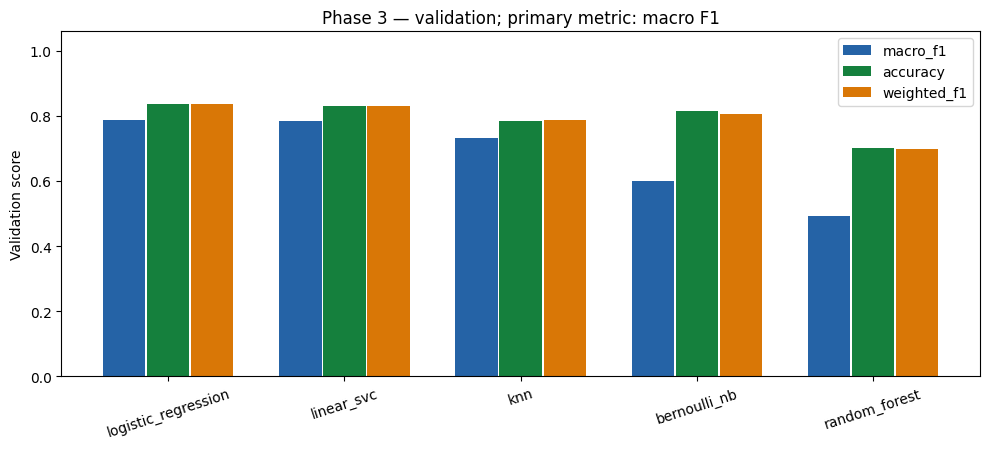

validation_performance → /content/drive/MyDrive/ML_Projects/disease-prediction-ml/reports/figures/phase3_baseline-v1-f8a5bfdb7b4c12cd_validation_performance.png


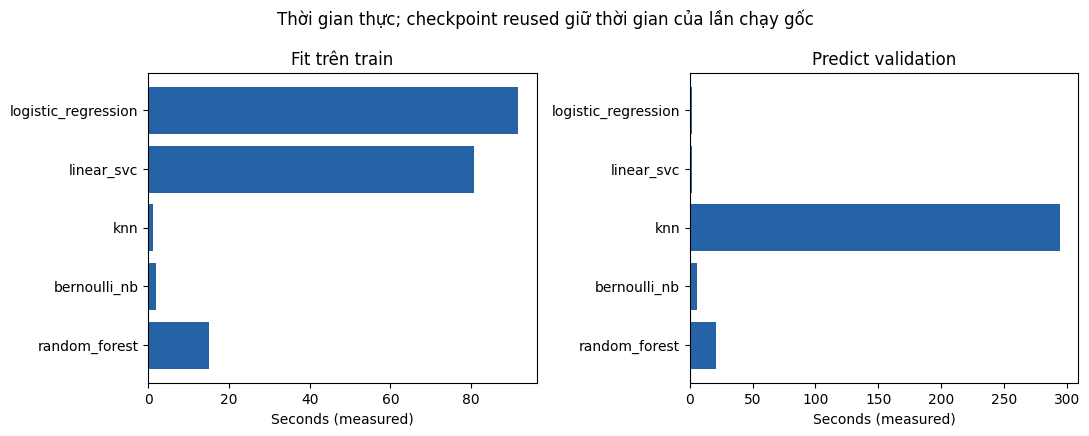

fit_prediction_time → /content/drive/MyDrive/ML_Projects/disease-prediction-ml/reports/figures/phase3_baseline-v1-f8a5bfdb7b4c12cd_fit_prediction_time.png


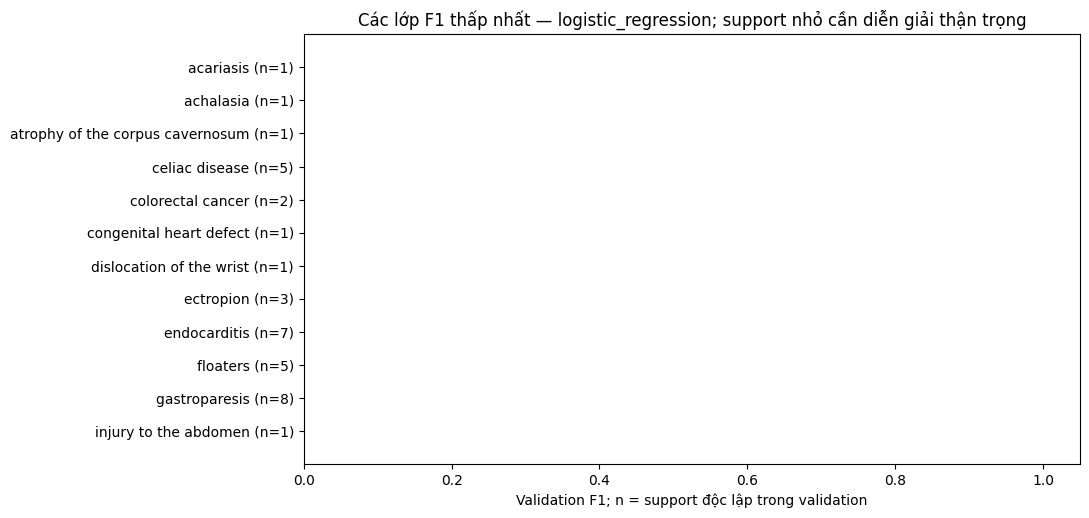

difficult_classes → /content/drive/MyDrive/ML_Projects/disease-prediction-ml/reports/figures/phase3_baseline-v1-f8a5bfdb7b4c12cd_difficult_classes.png
Comparison CSV: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/reports/tables/phase3_baseline-v1-f8a5bfdb7b4c12cd_validation_comparison.csv
Run metadata: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/artifacts/metadata/phase3/baseline-v1-f8a5bfdb7b4c12cd/run_summary.json
Phase 4 ready: True
Dừng sau Phase 3. Chưa mở/evaluate test hoặc train ensemble.


In [11]:
handoff = session.show_results()

## 5. Hyperparameter Tuning — thí nghiệm riêng, mặc định tắt

Baseline và output ở trên giữ nguyên. Phần này chỉ chạy khi bật công tắc bên dưới;
không cần chạy lại các cell fit baseline nếu chỉ muốn tuning: chạy setup, mở session và load_data, rồi tới đây.
Dùng **train-only StratifiedGroupKFold, 3 fold, seed 42**, cùng group IDs thật cho mọi candidate.
Macro F1 lấy đủ 587 lớp (`zero_division=0`), lớp vắng trong fold vẫn có F1=0;
coverage/warnings ghi trong metadata. `VarianceThreshold(0)` fit mới bên trong từng fold pipeline.
15 candidate × 3 fold = 45 fold fits, sau đó chọn bằng CV và fit một bản/model trên toàn train.
Validation chỉ đánh giá sau khi đã khóa cả 5 cấu hình. Không mở test hoặc thay model mặc định.

Search tuần tự, RF ≤2 workers, KNN 1 worker, BLAS 1, batch ≤64, working memory ≤128 MiB.
Budget 6 giờ chỉ kiểm giữa các fold (không ngắt cứng fold đang chạy); có thể Interrupt và resume.
Điểm fold lưu Drive, không lưu fold model. Checkpoint selected dùng cơ chế fit/resume hiện có.
Xem [giao thức và giới hạn tuning](../docs/MODEL_SELECTION_RATIONALE.md#hyperparameter-tuning-có-kiểm-soát).


In [3]:
RUN_HYPERPARAMETER_TUNING = True
from src.models.tuning import plan_table, run_tuning
from IPython.display import display, Image
import pandas as pd

display(plan_table(session.config))  # Chỉ hiển thị kế hoạch; chưa fit.


,model,candidate,baseline,parameters
0,logistic_regression,0,True,"{""C"": 1.0, ""max_iter"": 200, ""solver"": ""saga"", ..."
1,logistic_regression,1,False,"{""C"": 0.5, ""max_iter"": 200, ""solver"": ""saga"", ..."
2,logistic_regression,2,False,"{""C"": 2.0, ""max_iter"": 200, ""solver"": ""saga"", ..."
3,random_forest,0,True,"{""max_depth"": 24, ""max_features"": ""sqrt"", ""max..."
4,random_forest,1,False,"{""max_depth"": 16, ""max_features"": ""sqrt"", ""max..."
5,random_forest,2,False,"{""max_depth"": 32, ""max_features"": ""sqrt"", ""max..."
6,linear_svc,0,True,"{""C"": 1.0, ""dual"": ""auto"", ""max_iter"": 3000, ""..."
7,linear_svc,1,False,"{""C"": 0.5, ""dual"": ""auto"", ""max_iter"": 3000, ""..."
8,linear_svc,2,False,"{""C"": 2.0, ""dual"": ""auto"", ""max_iter"": 3000, ""..."
9,knn,0,True,"{""algorithm"": ""brute"", ""metric"": ""manhattan"", ..."


Đang đọc train/validation và kiểm tra schema/group...


,Tập,Bản ghi,Lớp bệnh,Triệu chứng trước variance,Group
0,train,131248,587,375,117211
1,validation,28120,587,375,25127


Fingerprint processed: afde00ce35bf4fd31c9c76edcc3c8b64104e53fb81dd98d4a56d7b3a884b16b3
VarianceThreshold chỉ fit khi train; cache ở ổ tạm: /content/disease-prediction-ml-cache/phase3/50308d250d874b1b
Experiment tuning-v1-9c4dd013abbba14a: train-only CV; 15 candidates × 3 folds.
CV logistic_regression | candidate 1/3 {'solver': 'saga', 'C': 1.0, 'max_iter': 200, 'tol': 0.001} | fold 1/3
RUNNING CV logistic_regression/0/0: 30s | peak RSS lấy mẫu 980.6 MiB | RAM khả dụng 10.81 GiB
RUNNING CV logistic_regression/0/0: 60s | peak RSS lấy mẫu 980.6 MiB | RAM khả dụng 10.80 GiB
  Validation: đã dự đoán 64/43,842 dòng
  Validation: đã dự đoán 43,842/43,842 dòng
  COMPLETED | 73.85s | F1=0.7832294869839925 | warnings=5
CV logistic_regression | candidate 1/3 {'solver': 'saga', 'C': 1.0, 'max_iter': 200, 'tol': 0.001} | fold 2/3
RUNNING CV logistic_regression/0/1: 30s | peak RSS lấy mẫu 981.0 MiB | RAM khả dụng 10.81 GiB
RUNNING CV logistic_regression/0/1: 60s | peak RSS lấy mẫu 981.0 MiB | RAM k

,model,candidate,fold_scores,mean_macro_f1,parameters,std_macro_f1
0,bernoulli_nb,1,"[0.6157458248630301, 0.626672374174179, 0.6216...",0.621363,"{'alpha': 0.5, 'binarize': None}",0.004466
1,knn,2,"[0.7234492854075428, 0.7278367891421647, 0.726...",0.725908,"{'algorithm': 'brute', 'metric': 'manhattan', ...",0.001830
2,linear_svc,2,"[0.7909086092224241, 0.793682390581234, 0.7952...",0.793277,"{'C': 2.0, 'dual': 'auto', 'max_iter': 3000, '...",0.001791
3,logistic_regression,2,"[0.8001498591475469, 0.8014715425436845, 0.800...",0.800571,"{'C': 2.0, 'max_iter': 200, 'solver': 'saga', ...",0.000637
4,random_forest,2,"[0.5212515192603765, 0.5109596238781603, 0.525...",0.519210,"{'max_depth': 32, 'max_features': 'sqrt', 'max...",0.006077


,fold,holdout_groups,holdout_rows,train_groups,train_rows,missing_train_classes,missing_holdout_classes
0,0,39071,43842,78140,87406,0,1
1,1,39073,43752,78138,87496,0,1
2,2,39067,43654,78144,87594,0,0


,baseline_macro_f1,baseline_validation_seconds,delta_macro_f1,model,tuned_macro_f1,tuned_validation_seconds
0,0.787808,2.157469,0.005346,logistic_regression,0.793154,2.115221
1,0.491997,20.683900,0.018911,random_forest,0.510908,20.876340
2,0.784222,1.826504,0.002146,linear_svc,0.786368,1.851988
3,0.731034,294.224154,0.014645,knn,0.745679,296.826149
4,0.599341,5.746997,0.072798,bernoulli_nb,0.672138,3.761508


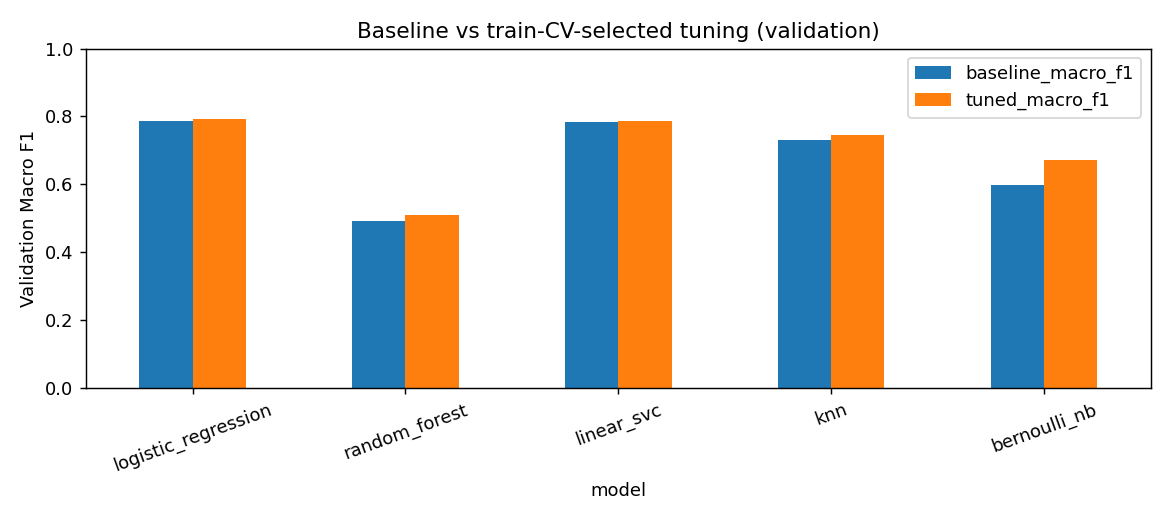

Warnings splitter: ['DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).']
Đã lưu manifest/checkpoints riêng trên Drive. LR ứng dụng chưa thay đổi; chưa mở test.


In [4]:
if RUN_HYPERPARAMETER_TUNING:
    tuning_result = run_tuning(session, enabled=True, trusted=True)
    print("Tuning experiment:", tuning_result["experiment_id"])
    display(pd.DataFrame([
        {"model": name, **selected}
        for name, selected in tuning_result["selection"].items()
    ]))
    display(pd.DataFrame([
        {**{k: v for k, v in fold.items() if not k.startswith("missing_")},
         "missing_train_classes": len(fold["missing_train_classes"]),
         "missing_holdout_classes": len(fold["missing_holdout_classes"])}
        for fold in tuning_result["fold_inventory"]
    ]))
    display(pd.DataFrame(tuning_result["comparison"]).round(6))
    display(Image(filename=str(runtime_paths.storage_root / "reports/tuning" /
                               tuning_result["experiment_id"] / "baseline_vs_tuned.png")))
    print("Warnings splitter:", tuning_result["split_warnings"])
    print("Đã lưu manifest/checkpoints riêng trên Drive. LR ứng dụng chưa thay đổi; chưa mở test.")
else:
    print("SKIPPED: RUN_HYPERPARAMETER_TUNING=False; không chạy CV hoặc fit tuned models.")


In [3]:
if "ROOT" not in globals():
    raise RuntimeError("Run the shared runtime setup first.")
from pathlib import Path

audit_file = (ROOT / 'scripts/audit_post_tuning.py')
print("File exists:", audit_file.is_file())

File exists: True


In [6]:
if "session" not in globals():
    raise RuntimeError("Run shared setup and ColabTraining.open(RUNTIME) first; do not run training to recreate session.")
import runpy
api = runpy.run_path(str(ROOT / 'scripts/audit_post_tuning.py'))
audit_result = api["audit_post_tuning"](
    session,
    experiment_id="tuning-v1-9c4dd013abbba14a",
    ensemble_run_id="tuned-ensemble-20261029T041701354242Z-6c84dbfe",
    trusted=True,
)
api["emit_packet"](audit_result)

AUDIT: checksums/schema/train-validation inputs
AUDIT: reproduce train-only grouped CV assignment (no fitting)
AUDIT: verify five selected pipelines and saved validation predictions
AUDIT: ensemble manifest, original hard-vote policy and saved metrics
POST_TUNING_SHA256=70849a69a0d2cd571e2d93a938b98a9167b9d46ceb0db9d6cb1859f6a2e415e8
POST_TUNING_GZIP_BASE64=H4sIAAAAAAAC/+2d+2/rxrHHf89fQeinFs1R9/1IbgsETYIbNDcNcpIUuEUh8LG0eSOJDimdE6fo/35nqdd+aVl+NElPXBrJsVekqNmdnc/M7M7a/3gvy2b5tmo2i77ddmVY9Ne50Gb2QTbzriwYY5bXVgRZy7IqmNKF4S4PpqxzK0MedClZKaWvCl95562XkmvDpJB69n58eNmubvKu6ds1PfNv9EqW/WP4N35wWW67vLylK2zupGWeM+kUM05Y//7hrnKZ933oFzVf/Bi6lm4W7nhxlZddS5eGR1hnHXNcMaGMVY6P7rrpQtn0zSAJfZ6wikeBvZX03Yxupnvz5XL3WOu5c1owZ7wS6iTZqq1CvGX2+VdZkfdh2azD7Hj1prkZXlkUt5vQ021cSSedPt3QhaopN6Fa7LtI99DYHa/3+Ru69iZfNlW+IbEX+zcs+lC266pf9NtVHI0511YZ55Rj8cva4xPehubqOn7AfoCcNMZqkoEZaZ0Ybvvn+5eVYgxjwinlNRPiklLkPUrxNCOo59wZ6YR6SCnSGUM3evpAYcUFpXihqMdWCeNpWvKzStls16F6QCPayAc0Yp6hEa6FYJY5T19cugsacYpmILecSy71YzRi6IFCeMYdDdFF

In [8]:
if not all(name in globals() for name in ("session", "api", "audit_result")):
    raise RuntimeError("Run setup and the preceding post-tuning audit cell first; no training required.")
import json, numpy as np
from collections import Counter
from sklearn.metrics import precision_recall_fscore_support
from src.models.ensemble import error_diversity

root = session.paths.storage_root.resolve()
with api['read_only'](root) as guard:
    result = api['read_tuning_result'](root, audit_result['experiment_id'])
    meta, models, _ = api['_paths'](root, result['experiment_id'])
    assert api['sha256_file'](meta/'manifest.json') == audit_result['tuning_manifest_sha256']
    trials = json.loads((meta/'trials.json').read_text())['trials']
    candidates = []
    for t in trials:
        last = {a['fold']: a for a in t['attempts']}
        assert set(last) == {0, 1, 2}
        assert all(a['status'] == 'completed' for a in last.values())
        scores = [last[k]['macro_f1'] for k in range(3)]
        candidates.append(dict(model=t['model'], candidate=t['candidate'], parameters=t['parameters'],
            fold_scores=scores, mean=float(np.mean(scores)), std=float(np.std(scores)),
            elapsed_seconds=sum(a['elapsed_seconds'] for a in t['attempts']),
            warnings=dict(Counter(w.split(':', 1)[0] for a in t['attempts'] for w in a.get('warnings', [])))))
    predictions = {}
    for name in api['MODEL_NAMES']:
        with np.load(models/name/'validation_predictions.npz', allow_pickle=False) as z:
            if not predictions:
                y, groups = z['y_true'].copy(), z['group_id'].copy()
            assert np.array_equal(z['y_true'], y) and np.array_equal(z['group_id'], groups)
            assert np.array_equal(z['row_0based'], np.arange(len(y)))
            predictions[name] = z['y_pred'].copy()
    em = root/'artifacts/metadata/runs'/audit_result['ensemble']['run_id']
    manifest_path = em/'tuned_ensemble_manifest.json'
    assert api['sha256_file'](manifest_path) == audit_result['ensemble']['manifest_sha256']
    manifest = json.loads(manifest_path.read_text())
    reports = root/'reports/runs'/audit_result['ensemble']['run_id']
    expected = [reports/'tables/tuned_validation_comparison.csv', em/'tuned_ensemble_predictions.npz',
                em/'tuned_results.json', reports/'tuned_ensemble_validation.md']
    api['verify_bundle'](root, manifest, [p.relative_to(root).as_posix() for p in expected])
    transitions, per_class = {}, {}
    lr = predictions['logistic_regression']
    with np.load(em/'tuned_ensemble_predictions.npz', allow_pickle=False) as z:
        assert np.array_equal(z['y_true'], y) and np.array_equal(z['group_id'], groups)
        assert np.array_equal(z['row_0based'], np.arange(len(y)))
        for name in (*api['HARD'], *api['SOFT']):
            p = z[name]
            transitions[name] = dict(corrects_lr=int(((lr != y) & (p == y)).sum()),
                loses_lr=int(((lr == y) & (p != y)).sum()),
                tie_rows=next(r['tie_rows'] for r in manifest['records'] if r['combination'] == name))
        for name, p in [('lr_tuned', lr), ('hard_lr_svc_knn', z['hard_lr_svc_knn'])]:
            _, _, f1, support = precision_recall_fscore_support(y, p, labels=np.arange(587), zero_division=0)
            per_class[name] = dict(f1=f1.tolist(), support=support.tolist())
    diversity = error_diversity(predictions, y, n_classes=587)
    diversity = {k: v.tolist() if isinstance(v, np.ndarray) else v for k, v in diversity.items()}
    supplement = dict(status='PASS', kind='model_analysis_supplement', experiment_id=result['experiment_id'],
        tuning_manifest_sha256=audit_result['tuning_manifest_sha256'],
        ensemble_manifest_sha256=audit_result['ensemble']['manifest_sha256'],
        candidates=candidates, transitions=transitions, diversity=diversity, per_class=per_class,
        models_fitted=0, prediction_called=False, test_payload_opened=False, guards=guard)
api['emit_packet'](supplement)

POST_TUNING_SHA256=4ccfa85ac4639778ffae6d11a435fb78af825bb4e1c294792356bec7236b4d28
POST_TUNING_GZIP_BASE64=H4sIAAAAAAAC/+1d23IbSXJ911dM4HlWUffLvjnsD3B4H/zgcCBAEpTgoQAagGZ2PLH/7pMgCWQWu5IlDEjJDpKYFgcNdNclLyezsk7/8eGnn2bXi/XN6maxX+5mf/3pP/DOTz/9cTjyczhlfn56d3m3uN8tb+a75fVmfUNfc85/dN5FZ102+HH++OHbzR0+eb3ZsuvTj/mYi3euhpJq8bW6+LM4V2r0LlWfgjPWiXOHk9XnmH1xIT2e+s/jLb8sF2tqMN0hVVdqrjkYk+zpE5ub5R0+MrvbfFrt9qvr+Xb5CS3crTbr2fFT94vt4styv9xSy/84tmD2z/hf+9Gc2jT7svj7fIUP0lAYfmK3ufv18PZst/i0mLEz+83doY3G2Mc3/3G88W5/83guWFtq8CG7aFNIp2H9bbFdr9afmpb9y/J+u7xe7NGNf3/4ADWVjd7s35a7zdft9fJ02j/d/gNrxKQEWEUCbLaQAGuyCzZU/OQRCYimJBdqMjak7KUEoM8mmxS8dwVCIM5h7o3xEWdx31wUCQgRA1iz8a7maOsFJcB8jG8hATH5EqAKtZQYQgznSEC9kAA4zQRU89FHDHdMNmL+08D8F3Q91BKrDTmGVH8W5/CmjcHF4BNGQJ4zpuKcSSa5GBULgE/GbGoxOcXiLjn97m0MgEk+O5g5DKnzMIbpLAsQLyQAmg+wPn6EpsIm2wLtNHZAAEIOzseS4QRiKiX8LM7BzmdbYU1c9TZ6cbIkqHSK2TpfS1IsQMjVl+hwH5ejj0yBjjKwRQ83X+a31MD9y7NPc32zvN9/pskOjRDcLhf7rw8dne3+e7ufNefvlovb+Rp3pk9EYZq/rNbz3eLL/d1yd/gYVzicXs/RutWXxX5zaJA1RvMb

In [9]:
if "session" not in globals():
    raise RuntimeError("Run shared setup and ColabTraining.open(RUNTIME) first; do not run training to recreate session.")
import runpy
read_api = runpy.run_path(str(ROOT / 'scripts/audit_post_tuning.py'))
gap_api = runpy.run_path(str(ROOT / 'scripts/audit_final_ml_gaps.py'))
gaps = gap_api['run_final_ml_gaps'](
    session, audit_api=read_api,
    benchmark=True, trusted=True,
)
gap_api['emit_packet'](gaps)

GAPS: checking pinned manifests and train/validation inputs
GAPS: paired group bootstrap; frozen seed20261029 / B2000
GAPS: benchmark lr_tuned (no fit)
GAPS: benchmark hard_lr_svc_knn (no fit)
ML_GAPS_SHA256=7c2ed8e6705347a850bb90e88cdea54067d0d12ec5553588ce03fbd0a99725ac
ML_GAPS_GZIP_BASE64=H4sIAAAAAAAC/+19WY/kuJXue/8KIV+mCuiK1L64YGB63G1PA9XtRnWP5+JeDAIMiRGhSkmUtURm1MD//X6HipAoisqlFk8/jGG7MniOKPLw7DwU//sby7rZ8So9lqy5u/mD9d9oQFMqqizvclG1Yxtaj6zJtkWzbU/p9q6qFBD1wrr06Mza0Fo3PMvTbtuJWofRa1hR0BucxP12DinZw7YkUBJtfDcJbM/Gf4Io1PHyasDz/U0YJoEXJUkSBm4YBRpmHdgXzHgT2T4QgJmg70RHTIIBMY43jutHse34iR95ka/g/WP8+x/T4zdFXuYdPXrza14dCm7VjUh5235r7fMHnlnv3r/pjrx6Q4S0RJPx5lsLJBAp60Rzm7L0yC2+3/O0wyMtK+sCD73/9VeLn3hztjdBa6Wsssq8ba2as7t2Y/2Wl8DpGla1e9GUtxeC355Ex99aJ1bkGaOFtNB3etdaou/aPONWh+eat1YlrO9++fEW6532TQNGON++e/fTbcW7e9HcYYzWr+++21jfs45ZDacnq87KK+v9dz+hd97k+xyvLwTLrLxFb52ViiKzvm/yE7fajjVdX29uFBKVvNzxZnt9dEuPbltODNfqzDPwmL2xfdv3YjeKwAKuH/uzFQPRK84kUw7IHjC8JPSxupEdJxqyOORtl6fbhh8wnxaUuTwV0nMRPRU6nusHxgVu2nb

## Experiment 1 — Baseline: đọc kết quả đã lưu

**Câu hỏi:** năm họ tuyến tính/margin/cây/láng giềng/Bernoulli khác nhau thế nào trên dữ liệu nhị phân? Giả thuyết so sánh thực nghiệm, không khẳng định ưu thế trước khi đo. Train 131.248 dòng, group-disjoint với validation; VarianceThreshold(0) fit train → 318/375 cột → CSR → classifier. Không fit trên validation. Cấu hình gốc: [phase3.json](../configs/phase3.json). LR C1/saga, SVC C1, RF depth24/100 cây, KNN k5/Manhattan/distance, NB alpha1.

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 | Weighted F1 |
|---|---:|---:|---:|---:|---:|
| logistic_regression | 0.83709104 | 0.82741979 | 0.77918852 | 0.78780814 | 0.83667539 |
| random_forest | 0.70053343 | 0.65965116 | 0.44122978 | 0.49199733 | 0.69931066 |
| linear_svc | 0.83079659 | 0.81520597 | 0.78139866 | 0.78422186 | 0.82986599 |
| knn | 0.78314367 | 0.78361997 | 0.73192046 | 0.73103438 | 0.78680402 |
| bernoulli_nb | 0.81486486 | 0.67229708 | 0.57387513 | 0.59934053 | 0.80525048 |

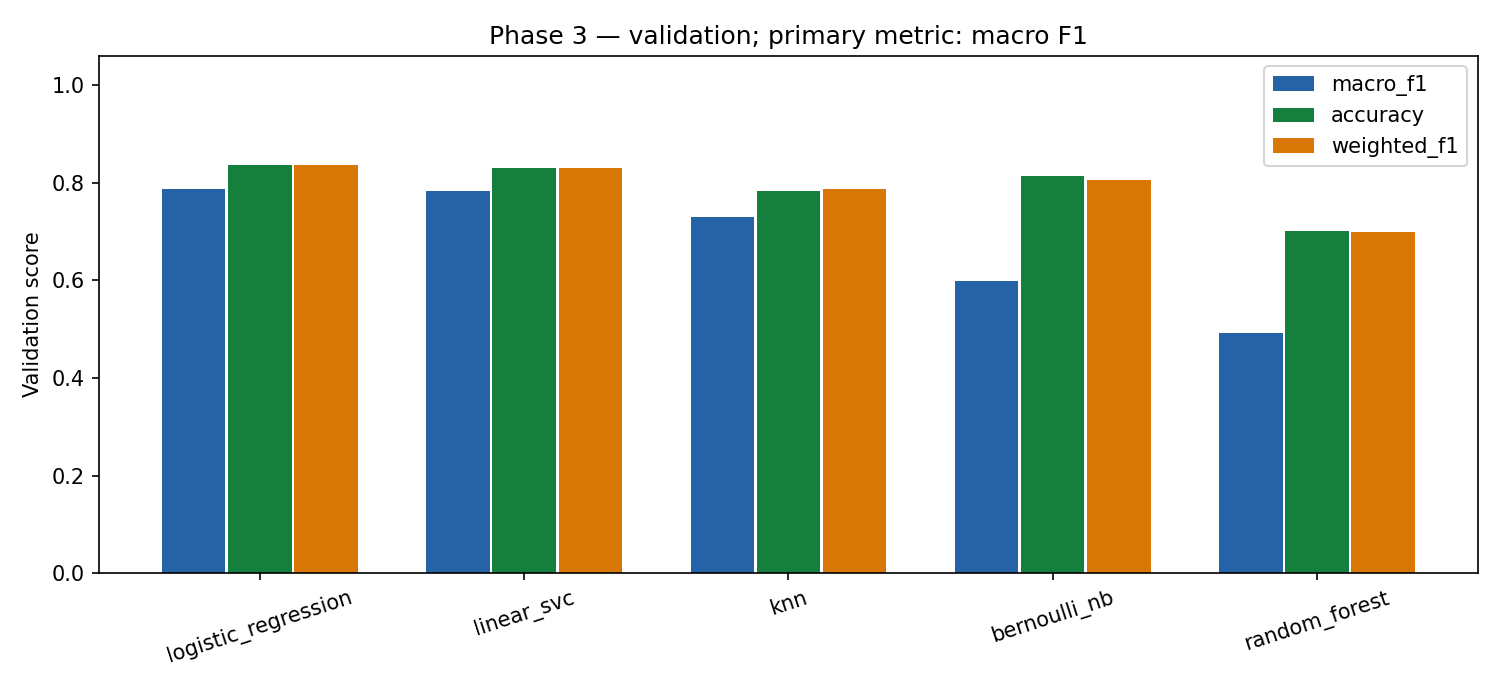

Hình đã có được giữ nguyên; giá trị chính xác và nguồn nằm trong bảng/caption này. LR là best baseline single theo Macro F1. Thời gian fit/predict cả validation và RSS đã lưu trong CSV; không diễn giải như batch1 latency.


Nguồn: saved CSV đối chiếu packets/manifests đã pin SHA; [figure_manifest.json](../reports/academic_review_20261111/figure_manifest.json) ghi checksum đầy đủ. **Validation 28.120 dòng, cố định 587 labels, zero_division=0**; không trộn final test. Chỉ đọc Markdown/output để trình bày; không Run All.
## Experiment 3 — Hyperparameter Tuning: xem kết quả không chạy search

Train-only StratifiedGroupKFold3, shuffle/seed42; 15 candidates × 3 folds. Scorer đủ587 labels/zero_division0; VT fit riêng train fold. Train coverage587/587/587, holdout586/586/587. Selection bằng CV trước đánh giá validation. Giữ search-space/selected-config trong manifest pin; LR C2, SVC C2, RF depth32, KNN k7, NB alpha0.5. Không phải neural-network fine-tuning.

| Model | Baseline Macro F1 | Tuned Macro F1 | Delta | Diễn giải |
|---|---:|---:|---:|---|
| logistic_regression | 0.78780814 | 0.79315438 | +0.00534624 | Tăng |
| random_forest | 0.49199733 | 0.51090813 | +0.01891080 | Tăng |
| linear_svc | 0.78422186 | 0.78636758 | +0.00214572 | Tăng |
| knn | 0.73103438 | 0.74567902 | +0.01464464 | Tăng |
| bernoulli_nb | 0.59934053 | 0.67213832 | +0.07279779 | Tăng |

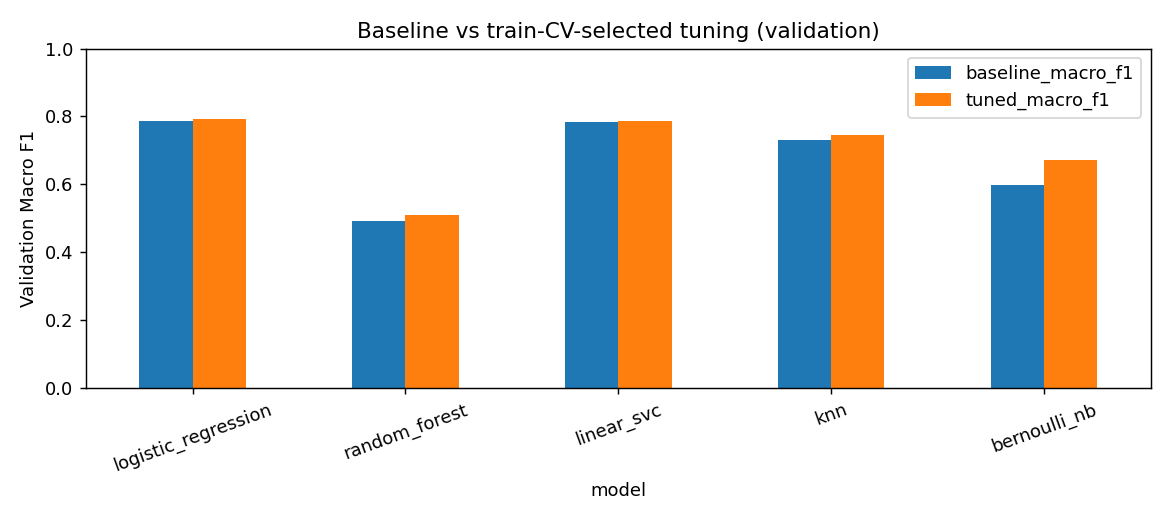

Cả5 tăng trong search space đã thử, không có model giảm Macro F1 validation. NB tăng nhiều nhất nhưng LR vẫn tốt nhất trong single models. 45 attempts hoàn tất, không convergence warning; fold predictions không persist nên không tuyên bố tái tính độc lập fold scores. State/resume khác training: chỉ xem saved manifest/report không chạy `run_tuning`. **Đính chính gate:** tài liệu gốc mô tả mặc định OFF; cell `tuning-switch` đang giữ True từ owner execution. Không sửa source đã chạy hoặc gán output cũ cho code mới. Đọc phần Markdown này để xem kết quả, không chạy cell tuning.


Nguồn: saved CSV đối chiếu packets/manifests đã pin SHA; [figure_manifest.json](../reports/academic_review_20261111/figure_manifest.json) ghi checksum đầy đủ. **Validation 28.120 dòng, cố định 587 labels, zero_division=0**; không trộn final test. Chỉ đọc Markdown/output để trình bày; không Run All.


### Search space đã chạy (không mở rộng)

| Họ | Ba candidates; phần còn lại giữ baseline | Selected |
|---|---|---|
| LR | C=1/0.5/2 | C=2 |
| LinearSVC | C=1/0.5/2 | C=2 |
| RF | max_depth=24/16/32 | 32 |
| KNN | k=5/3/7 | 7 |
| BernoulliNB | alpha=1/0.5/2 | 0.5 |

Nguồn đầy đủ candidate parameters/fold scores: pinned `artifacts/metadata/model_analysis/colab_supplement.json`; phase3 config không bị sửa. Tuning train-only, validation không dùng search. Giới hạn: 3 candidates/family, không là exhaustive optimum; time budget kiểm giữa folds, warnings/resume lưu metadata. Không cần bật gate để xem bảng này.
